In [891]:
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.nn as nn
import numpy as np

In [892]:
random.seed(42)
file_string = open('names.txt','r').read()
names = list(file_string.split('\n'))

In [893]:
# defining the character mappings: ctoi and itoc
chars = sorted(list(set(''.join(names))))
ctoi = {c: i+1 for i,c in enumerate(chars)}
ctoi['.'] = 0
itoc = {i: c for c, i in ctoi.items()}

In [894]:
print(f"{ctoi}")
print(f"{itoc}")

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [895]:
context_size = 4
input_context_size = context_size - 1
no_dims = 10
no_l0 = input_context_size*no_dims
no_l1 = 200
no_l2 = len(ctoi)
learning_rate = 0.1
batch_size = 32

In [896]:
def build_dataset(words):
    X = []
    Y = []

    random.shuffle(words)
    for word in words:
        context = [ctoi['.']] * input_context_size
        idx = 0
        word = word + '.'

        for ch in word:
            X.append(context)
            Y.append(ctoi[ch])

            context = context[1:] + [ctoi[ch]]

    # for i in range(len(X)):
    #     print(f"{''.join(itoc[j] for j in X[i])} ----> {itoc[Y[i]]}")

    X = torch.tensor(X)
    Y = torch.tensor(Y)

    return X, Y

In [897]:
random.shuffle(names)
dataset = names
cut_1 = int(0.8*len(dataset))
cut_2 = int(0.9*len(dataset))
Xtr, Ytr = build_dataset(dataset[:cut_1])
Xdev, Ydev = build_dataset(dataset[cut_1:cut_2])
Xtest, Ytest = build_dataset(dataset[cut_2:])

print(f"{len(Xtr)}, {len(Ytr)}, {len(Xdev)}, {len(Ydev)}, {len(Xtest)}, {len(Ytest)}")

182625, 182625, 22655, 22655, 22866, 22866


In [898]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility

In [899]:
# Setup all the parameters

## Create embedding matrix for every character based on no_dims
embed_table = torch.randn((len(ctoi), no_dims), generator=g)

## Hidden layer weights and biases
W1 = torch.randn((no_l0, no_l1), generator=g)
b1 = torch.randn((no_l1), generator=g)

## Output layer weights and biases
W2 = torch.randn((no_l1, no_l2), generator=g)
b2 = torch.randn((no_l2), generator=g)

parameters = [embed_table, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

print(f"{W1.shape} {W2.shape}")

torch.Size([30, 200]) torch.Size([200, 27])


In [900]:
# Define the forward_pass, calculate_loss and gradient_descent

def forward_pass(input_context, params):

    embed_table, W1, b1, W2, b2 = params
    # Shape: (batch_size, no_l0)
    # Eg: (16, 2*3) where 2 is the no of dimensions and 3 is the input context size
    emb = embed_table[input_context].view(-1, no_l0) # Using emb.view instead of .concat function

    # Layer 1 (hidden layer)
    # emb: (16, 6)
    # W1: (6, 100)
    # b1: (100)
    # result => (16, 100)
    h_out = torch.tanh(emb @ W1 + b1)

    # Layer 2 (output layer)
    # h_out: (16, 100)
    # W2: (100, 27)
    # b2: (27)
    # result => (16, 27)
    logits = h_out @ W2 + b2
    
    return logits

def calculate_loss(logits, expected):
    return F.cross_entropy(logits, expected)

def gradient_descent(loss, lr, params):
    for p in params:
        p.grad = None
    loss.backward()

    for p in params:
        p.data += -lr * p.grad

In [901]:
losses = []
steps = []

In [902]:
Xtr.shape

torch.Size([182625, 3])

In [903]:
def train(repititions=100000, lr = 0.1):
    print(f"repititions: {repititions}, lr={lr}")
    for i in range(repititions):

        # Construct mini batch
        # low=0, high=Xtr.shape[0], shape=(batch_size,)
        # randint gets values between low and high in the necessary shape
        ixs = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
        input_contexts = Xtr[ixs]
        outputs = Ytr[ixs]
    
        logits = forward_pass(input_contexts, parameters)
        batch_losses = calculate_loss(logits, outputs)
        gradient_descent(batch_losses, lr, parameters)
    
        losses.append(batch_losses.item())
        steps.append(i)

In [904]:
for i in range(8):
    if i >= 4:
        learning_rate = 0.01
    train(25000, learning_rate)

print(f"First loss: {losses[0]}")

repititions: 25000, lr=0.1
repititions: 25000, lr=0.1
repititions: 25000, lr=0.1
repititions: 25000, lr=0.1
repititions: 25000, lr=0.01
repititions: 25000, lr=0.01
repititions: 25000, lr=0.01
repititions: 25000, lr=0.01
First loss: 24.618446350097656


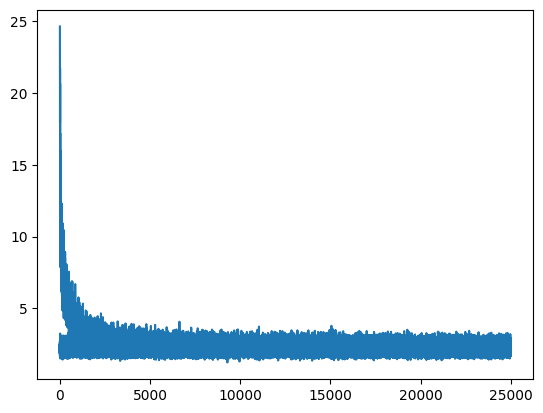

In [905]:
plt.plot(steps, losses)

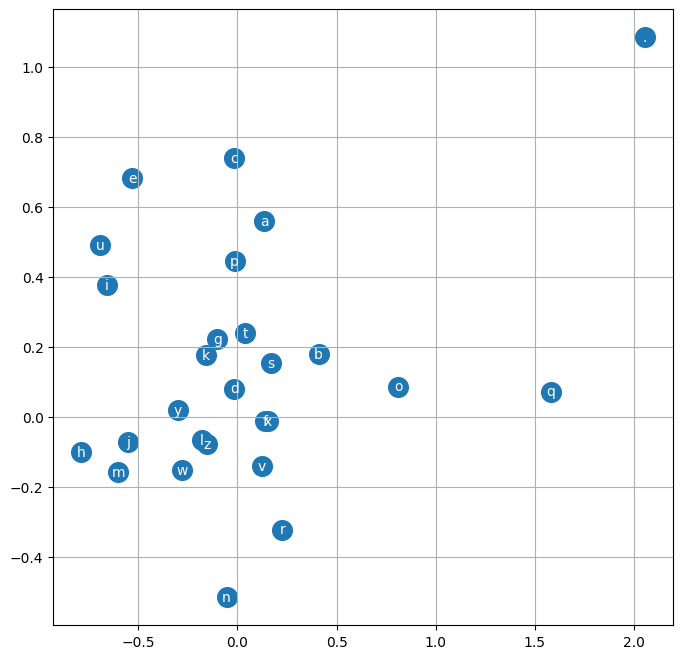

In [906]:
plt.figure(figsize=(8,8))
plt.scatter(embed_table[:,0].data, embed_table[:,1].data, s=200)
for i in range(embed_table.shape[0]):
    plt.text(embed_table[i,0].item(), embed_table[i,1].item(), itoc[i], ha="center", va="center", color='white')
plt.grid('minor')

In [907]:
def test_against_training():
    logits = forward_pass(Xtr, parameters)
    loss = calculate_loss(logits, Ytr)
    print(f"Loss when tested against training: {loss}")
    return loss

test_against_training()

Loss when tested against training: 2.125821590423584


tensor(2.1258, grad_fn=<NllLossBackward0>)

In [908]:
def test_against_dev():
    logits = forward_pass(Xdev, parameters)
    loss = calculate_loss(logits, Ydev)
    print(f"Loss when tested against dev: {loss}")
    return loss

test_against_dev()

Loss when tested against dev: 2.153965711593628


tensor(2.1540, grad_fn=<NllLossBackward0>)

In [911]:
def generate():
    context = [ctoi['.']] * input_context_size
    res = []
    while True:
        logits = forward_pass(context, parameters)
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        res.append(ix)

        if ix == 0:
            break
    return ''.join(itoc[i] for i in res)

for _ in range(20):
    print(generate())
    

binza.
invilian.
kamiren.
ka.
denna.
maylan.
vion.
halia.
ella.
javo.
madiah.
avras.
harleri.
aarion.
karah.
prigob.
layla.
voey.
yosamarcitto.
traxt.


In [910]:
# Results of loss with the following default values:
# context_size = 4
# input_context_size = context_size - 1
# no_dims = 2
# no_l0 = input_context_size*no_dims
# no_l1 = 100
# no_l2 = len(ctoi)
# learning_rate = 0.1
# batch_size = 16

#### The dev loss after a single pass of training is 2.3790

# Changing batch_size to 32
## I expect that the loss will go down atleast by a bit. This is obvious
## since I am training double the number of examples.

#### The dev loss after a single pass of training is 2.3160
#### Funnily enough, `u` is considered an outlier compared to all other letters
#### including vowels

# Changing learning rate and training twice
## first pass of training, learning_rate = 0.1
## second pass of training, learning_rate = 0.01
## batch_size is still 32

## Again, I only expect the loss to decrease since I am training twice.
## It would be insightful to check at what point the learning_rate
## should be modified instead of changing between training passes
## in a random manner.

#### The dev loss after a single pass of training is 2.2535